In [103]:
!unzip -o UofU_project.zip
!cp -r UofU_project/data .

Archive:  UofU_project.zip
  inflating: UofU_project/data/efia2022.csv  
  inflating: UofU_project/data/f2223_f1a_rv.csv  
  inflating: UofU_project/data/efia2023_RV.csv  
  inflating: UofU_project/data/f2223_f1a.csv  
  inflating: UofU_project/data/efia2022_rv.csv  
  inflating: UofU_project/data/efia2023.csv  
  inflating: UofU_project/data/f2122_f1a.csv  
  inflating: UofU_project/data/hd2024.csv  
  inflating: UofU_project/data/f2324_f1a.csv  
  inflating: UofU_project/data/efia2024_rv.csv  
  inflating: UofU_project/data/f2122_f1a_rv.csv  
  inflating: UofU_project/data/efia2024.csv  
  inflating: UofU_project/UofU_admin_costs_starter.ipynb  


# What Drives Administrative Costs at Universities? A Case Study of the University of Utah

**Group members:** Edson Marquez, Aaron Iverson, Dakota Meier, Rj Mryzglod, Gerson Perez

**Video presentation:** [YouTube link here]

## Project overview
The University of Utah plans to eliminate 285 to 855 operational staff positions, has cut retirement benefits for new hires, and is closing its Sandy campus. This project uses public data on U.S. public universities to model what drives spending on administration, then checks where the University of Utah falls compared with what the model predicts for a school like it.

**Goal:** help university leaders see where consolidation of administrative functions looks sustainable and where the U already runs lean.

# 1. Business Understanding (CRISP-DM)

## The organization
The University of Utah is the state's flagship public research university. It has about 47,000 employees, including U of U Health, and an anticipated budget of $10.6 billion for fiscal 2027 [1]. Fall 2025 enrollment was a record 38,300 students [3].

## The business challenge
- The university says expenses are outpacing revenue and expects enrollment to decline by 2032 [1].
- In the audited FY2025 statements, operating expenses were about $8.59 billion against $8.14 billion in operating revenue, and compensation and benefits were about $4.44 billion (roughly 52% of operating expenses) [3].
- In response, the university plans to eliminate 285 to 855 operational staff positions (5% to 15% of 5,700 positions under review). Faculty and U of U Health are not part of this first round [1][2].
- It has also cut retirement benefits for new employees and is closing its Sandy campus [1].

## Why it matters
Administrative staffing is one of the few large costs a university can restructure. Cutting too deep can hurt recruiting, retention, and service to students. Cutting too little leaves a budget gap. Leaders need an evidence-based way to judge what "lean" looks like for a school like theirs.

## Industry and market factors
Federal research funding is uncertain, changes to Medicaid affect academic health systems, and state funding is under pressure [1][3]. Many universities are making similar cuts.

# 2. Data Sources and References

**Datasets**
- **IPEDS (Integrated Postsecondary Education Data System), NCES** - https://nces.ed.gov/ipeds/use-the-data. Federal data that every U.S. college reports each year. We use the Institutional Characteristics (directory), Finance, and 12-month Enrollment files. This is the main modeling dataset.
- **Utah State Auditor, University of Utah FY2025 Annual Financial Report** - audited statements for the U, used for background and to sanity-check the model against the university's own numbers [3].
- **College Scorecard (optional)** - https://collegescorecard.ed.gov/data/. Extra cost and outcome variables if we use them.

**References**
1. "https://www.sltrib.com/news/education/2026/09/15/university-utah-plans-lay-off/" (Septemeber 15, 2026)
2. Fox 13, "University of Utah to cut hundreds of job positions in 'modernization effort'" - https://www.fox13now.com/news/local-news/salt-lake-city/university-of-utah-to-cut-hundreds-of-job-positions-in-modernization-effort
3. University of Utah, *2025 Annual Financial Report*, audited by the Office of the Utah State Auditor (November 21, 2025).

# 3. Data Understanding

## Step 1: Load the libraries
We use pandas for tables, numpy for math, matplotlib and seaborn for charts, and scikit-learn for the models.

In [104]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2: Settings in one place
Everything that might need to change lives in this one cell: the data folder, the years, the University of Utah's ID, and the IPEDS column names. The finance codes were checked against the University of Utah's own audited numbers (for example, `F1B01` matches the audit report's net tuition and `F1B11` matches its state appropriations). The enrollment codes (`FTEUG`, `FTEGD`, `FTEDPP`) were checked against the enrollment file: adding all three gives the University of Utah's 2024 institutional support per FTE student of $12,006, exactly matching IPEDS's own published figure. `FTEDPP` counts doctoral professional practice students (for example medical and law students).

In [105]:
DATA_DIR = 'data'                        # folder with the unzipped IPEDS CSV files
YEARS = [2022, 2023, 2024]               # data years: finance files f2122, f2223, f2324
HD_YEAR = 2024                           # one directory file supplies school type, level, hospital flag
UOFU_ID = 230764                         # University of Utah's UNITID

COLS = {                                 # friendly name : IPEDS column
    'inst_support': 'F1C071',            # institutional support expenses (finance file)
    'instruction':  'F1C011',            # instruction expenses (finance file)
    'research':     'F1C021',            # research expenses (finance file)
    'tuition':      'F1B01',             # net tuition and fees revenue (finance file)
    'state_approp': 'F1B11',             # state appropriations (finance file)
    'fte_ug':       'FTEUG',             # undergraduate FTE enrollment (enrollment file)
    'fte_gr':       'FTEGD',             # graduate FTE enrollment (enrollment file)
    'fte_dpp':      'FTEDPP',            # doctoral professional practice FTE, e.g. medical and law students (enrollment file)
}

## Step 3: A small helper to read an IPEDS file
IPEDS files are named by year, and some years have both an original and a revised file (suffix `_rv`). This helper finds the file by pattern, uses the revised one when both exist, reads it, and tidies the column names (removes stray characters and spaces, makes them uppercase).

In [106]:
def read_ipeds(pattern):
    path = sorted(glob.glob(f'{DATA_DIR}/{pattern}'))[-1]         # find the file; prefer the revised (_rv) one
    df = pd.read_csv(path, encoding='latin-1', low_memory=False)  # IPEDS files use latin-1 text
    df.columns = df.columns.str.replace('ï»¿', '').str.strip().str.upper()
    return df

## Step 4: Look at one year first
Before combining years, we load the directory file and the most recent year's finance and enrollment files, and check their sizes. The finance file name uses a school-year pattern (for example, `f2223` for 2022-23), so we build that part from the year.

In [107]:
y = YEARS[-1]
hd  = read_ipeds(f'hd{HD_YEAR}*.csv')                             # directory: names, type, hospital flag
fin = read_ipeds(f'f{str(y-1)[-2:]}{str(y)[-2:]}_f1a*.csv')       # finance for public institutions
enr = read_ipeds(f'efia{y}*.csv')                                 # 12-month enrollment (FTE)
print('directory:', hd.shape, '| finance:', fin.shape, '| enrollment:', enr.shape)

directory: (6072, 72) | finance: (1911, 288) | enrollment: (5861, 18)


## Step 5: Check that our column names exist
This catches typos and wrong IPEDS codes right away, before they cause errors later. Any name printed in the lists below needs to be fixed in the settings cell.

In [108]:
needed = {
    'hd':  ['UNITID', 'INSTNM', 'STABBR', 'CONTROL', 'ICLEVEL', 'HOSPITAL', 'MEDICAL'],
    'fin': ['UNITID', COLS['inst_support'], COLS['instruction'], COLS['research'], COLS['tuition'], COLS['state_approp']],
    'enr': ['UNITID', COLS['fte_ug'], COLS['fte_gr'], COLS['fte_dpp']],
}
frames = {'hd': hd, 'fin': fin, 'enr': enr}
for name, cols in needed.items():
    print(name, 'missing columns:', [c for c in cols if c not in frames[name].columns])

hd missing columns: []
fin missing columns: []
enr missing columns: []


## Step 6: Combine the three files for every year
We read the directory file once (school type and hospital flag change rarely). For each year we keep only the finance and enrollment columns we need and merge everything on `UNITID`, the unique ID IPEDS gives every institution. Then we stack the years into one table (a panel: one row per school per year).

In [109]:
hd = hd[needed['hd']]                                              # keep only the directory columns we need
def load_year(y):
    fin = read_ipeds(f'f{str(y-1)[-2:]}{str(y)[-2:]}_f1a*.csv')[needed['fin']]
    enr = read_ipeds(f'efia{y}*.csv')[needed['enr']]
    df = fin.merge(enr, on='UNITID').merge(hd, on='UNITID')
    df['YEAR'] = y
    return df

In [110]:
df_raw = pd.concat([load_year(y) for y in YEARS], ignore_index=True)
df_raw = df_raw.rename(columns={v: k for k, v in COLS.items()})   # use friendly names from here on
print(df_raw.shape)
df_raw.head()

(5544, 16)


,UNITID,inst_support,instruction,research,tuition,state_approp,fte_ug,fte_gr,fte_dpp,INSTNM,STABBR,CONTROL,ICLEVEL,HOSPITAL,MEDICAL,YEAR
0,100654,23566167,34969711,13021062,52768565,53817222,4315.0,629.0,NaN,Alabama A & M University,AL,1,1,2,2,2022
1,100663,239373162,315434909,360236807,238778078,332448930,12105.0,7160.0,1411.0,University of Alabama at Birmingham,AL,1,1,1,1,2022
2,100706,21700323,71728665,127677705,75541635,58322523,6847.0,1270.0,83.0,University of Alabama in Huntsville,AL,1,1,2,2,2022
3,100724,41065705,36266697,4489287,35863560,55021738,3394.0,413.0,72.0,Alabama State University,AL,1,1,2,2,2022
4,100751,119034755,311837789,169667611,485015783,194970221,29637.0,4693.0,619.0,The University of Alabama,AL,1,1,2,2,2022


## Step 7: Narrow to our comparison group
The University of Utah is a public university that offers four-year degrees, so we compare it with other public four-year institutions. In IPEDS, `CONTROL == 1` means public and `ICLEVEL == 1` means four-year or above. We then check that we still have enough rows for modeling (the assignment asks for thousands of rows).

In [111]:
df = df_raw[(df_raw['CONTROL'] == 1) & (df_raw['ICLEVEL'] == 1)].copy()
print('rows:', df.shape[0], '| columns:', df.shape[1], '| unique schools:', df['UNITID'].nunique())
print(df.groupby('YEAR').size())

rows: 2394 | columns: 16 | unique schools: 799
YEAR
2022    797
2023    798
2024    799
dtype: int64


## Step 8: Find the University of Utah
We confirm the U appears in every year, since we will compare it with the model later.

In [112]:
df[df['UNITID'] == UOFU_ID][['YEAR', 'INSTNM', 'inst_support', 'fte_ug', 'fte_gr', 'fte_dpp']]

,YEAR,INSTNM,inst_support,fte_ug,fte_gr,fte_dpp
1386,2022,University of Utah,290570000,23355.0,6119.0,1711.0
3237,2023,University of Utah,364122000,24173.0,5988.0,1745.0
5086,2024,University of Utah,397553000,25330.0,6011.0,1771.0


# 4. Exploratory Data Analysis (EDA)

## Step 9: Initial inspection
Column types and non-missing counts. We look for columns that should be numbers but are stored as text, and columns with many blanks.

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2394 entries, 0 to 5542
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   UNITID        2394 non-null   int64  
 1   inst_support  2394 non-null   int64  
 2   instruction   2394 non-null   int64  
 3   research      2394 non-null   int64  
 4   tuition       2394 non-null   int64  
 5   state_approp  2394 non-null   int64  
 6   fte_ug        2363 non-null   float64
 7   fte_gr        1656 non-null   float64
 8   fte_dpp       907 non-null    float64
 9   INSTNM        2394 non-null   object 
 10  STABBR        2394 non-null   object 
 11  CONTROL       2394 non-null   int64  
 12  ICLEVEL       2394 non-null   int64  
 13  HOSPITAL      2394 non-null   int64  
 14  MEDICAL       2394 non-null   int64  
 15  YEAR          2394 non-null   int64  
dtypes: float64(3), int64(11), object(2)
memory usage: 318.0+ KB


## Step 10: Summary statistics

In [114]:
df.describe().T.round(0)

,count,mean,std,min,25%,50%,75%,max
UNITID,2394.0,194999.0,72698.0,100654.0,145813.0,190637.0,226091.0,4.985710e+05
inst_support,2394.0,38504464.0,57125307.0,0.0,8986316.0,19093316.0,43053744.0,5.348310e+08
instruction,2394.0,127723676.0,236507729.0,0.0,21897886.0,52031704.0,128136555.0,3.589365e+09
research,2394.0,60769709.0,179525309.0,0.0,0.0,1055326.0,17922056.0,1.580197e+09
tuition,2394.0,93258845.0,178668555.0,0.0,9541130.0,29430916.0,82136646.0,2.028283e+09
state_approp,2394.0,90271524.0,128996402.0,0.0,17550581.0,44245264.0,103305682.0,1.226190e+09
fte_ug,2363.0,8227.0,9224.0,6.0,2124.0,4931.0,9896.0,6.626200e+04
fte_gr,1656.0,1928.0,2675.0,0.0,336.0,1038.0,2385.0,2.179900e+04
fte_dpp,907.0,743.0,990.0,0.0,88.0,391.0,995.0,5.797000e+03
CONTROL,2394.0,1.0,0.0,1.0,1.0,1.0,1.0,1.000000e+00


## Step 11: Missing values

In [115]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

,0
fte_dpp,1487
fte_gr,738
fte_ug,31


## Step 12: Distribution of institutional support spending
Institutional support is the IPEDS category for central administration. Total dollars depend heavily on school size, so we expect a long right tail.

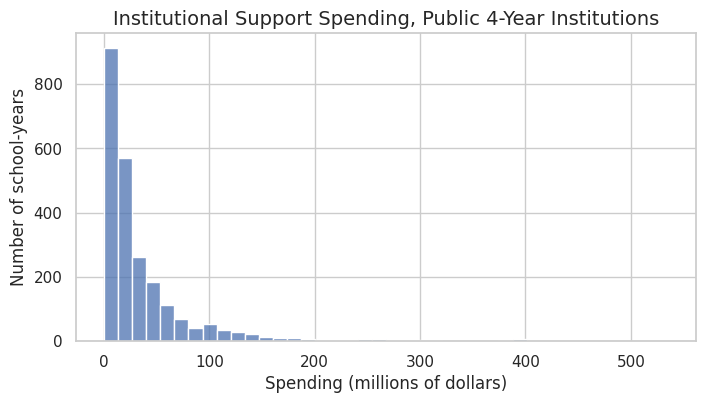

In [116]:
plt.figure(figsize=(8, 4))
sns.histplot(df['inst_support'] / 1e6, bins=40)
plt.title('Institutional Support Spending, Public 4-Year Institutions')
plt.xlabel('Spending (millions of dollars)'); plt.ylabel('Number of school-years')
plt.show()

# 5. Data Preparation

## Data smells: find, fix, and re-check
Following the Week 6 data smells workbook, we scan the data for common smells, fix each one in Python, and re-run the same scan to confirm the fixes worked. The scan checks five smells. Document the three it actually finds in your data.

1. **Dummy values (believability):** IPEDS uses negative codes such as -1, -2, and -3 to mean "not reported" or "not applicable". Left in, they look like real numbers.
2. **Zeros that mean "no data" (believability):** a school that reports $0 of institutional support is not running administration for free.
3. **Entities that are not teaching campuses (consistency):** system offices and research centers appear in the finance file with no instruction spending, so per-student comparisons with real campuses make no sense.
4. **Numbers stored as text (encoding):** a stray character such as "." turns a numeric column into text.
5. **Stray spaces in names (syntactic):** extra spaces make the same name look like different values.

### Step 13: Scan for the smells (before cleaning)

In [117]:
def smell_scan(d):
    num = d.select_dtypes('number')
    text_cols = d.select_dtypes(exclude='number').columns
    text_numeric = [c for c in text_cols if pd.to_numeric(d[c], errors='coerce').notna().mean() > 0.9]
    return {'dummy codes (-9 to -1)': int(num.isin(range(-9, 0)).sum().sum()),
            'rows with $0 institutional support': int((d['inst_support'] == 0).sum()),
            'rows with $0 instruction (non-teaching entities)': int((d['instruction'] == 0).sum()),
            'numeric columns stored as text': len(text_numeric),
            'names with stray spaces': int((d['INSTNM'] != d['INSTNM'].str.strip()).sum())}
before = smell_scan(df)
before

{'dummy codes (-9 to -1)': 0,
 'rows with $0 institutional support': 4,
 'rows with $0 instruction (non-teaching entities)': 3,
 'numeric columns stored as text': 0,
 'names with stray spaces': 0}

### Step 14: Fix smell 1 - dummy codes become missing values
First we make sure the money and enrollment columns are real numbers (`errors='coerce'` turns anything that is not a number into `NaN`, Python's "missing"). Then we see which columns hold dummy codes and replace them with `NaN` so they are not treated as real amounts.

In [118]:
num_cols = ['inst_support', 'instruction', 'research', 'tuition', 'state_approp', 'fte_ug', 'fte_gr', 'fte_dpp']
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')
num = df.select_dtypes('number').columns
codes = df[num].isin(range(-9, 0)).sum()
print(codes[codes > 0])                                   # where the dummy codes are
df[num] = df[num].mask(df[num].isin(range(-9, 0)))        # turn them into missing values
print('dummy codes left:', df[num].isin(range(-9, 0)).sum().sum())

Series([], dtype: int64)
dummy codes left: 0


### Step 15: Fix smell 2 - $0 institutional support becomes missing
A zero here means the school did not report the number, so we mark it as missing. Step 18 will remove rows with a missing target.

In [119]:
print('zero institutional support:', (df['inst_support'] == 0).sum())
df.loc[df['inst_support'] == 0, 'inst_support'] = np.nan
print('remaining:', (df['inst_support'] == 0).sum())

zero institutional support: 4
remaining: 0


### Step 16: Fix smell 3 - remove entities that are not teaching campuses
These are not comparable with real campuses, so we list a few examples and then drop them. We also tidy stray spaces in names.

In [120]:
print(df.loc[df['instruction'] == 0, 'INSTNM'].drop_duplicates().head(8).tolist())
df = df[df['instruction'] > 0].copy()
df['INSTNM'] = df['INSTNM'].str.strip()
print('rows left:', len(df))

['Thomas Edison State University']
rows left: 2391


### Step 17: Re-validate - run the same scan after cleaning
The "after" column should show zero for each smell we fixed.

In [121]:
after = smell_scan(df)
pd.DataFrame({'before': before, 'after': after})

,before,after
dummy codes (-9 to -1),0,0
rows with $0 institutional support,4,0
rows with $0 instruction (non-teaching entities),3,0
numeric columns stored as text,0,0
names with stray spaces,0,0


## Missing values
### Step 18: Decide what to do with the blanks
We cannot compute spending per student without the spending amount and the enrollment, so rows missing those are dropped. Graduate and doctoral professional FTE blank most likely mean no such students, so we fill them with 0. For the other features we fill blanks with the median, the same approach used in class.

In [122]:
print('rows before:', len(df))
df = df.dropna(subset=['inst_support', 'fte_ug']).copy()
df[['fte_gr', 'fte_dpp']] = df[['fte_gr', 'fte_dpp']].fillna(0)
for c in ['research', 'tuition', 'state_approp']:
    df[c] = df[c].fillna(df[c].median())
print('rows after:', len(df))

rows before: 2391
rows after: 2356


### Step 19: Remove duplicates
Each school should appear once per year.

In [123]:
print('duplicate school-years:', df.duplicated(subset=['UNITID', 'YEAR']).sum())
df = df.drop_duplicates(subset=['UNITID', 'YEAR'])

duplicate school-years: 0


## Feature engineering
### Step 20: Build the target and the features
Big schools spend more in total, so comparing total dollars is unfair. We divide by full-time-equivalent (FTE) students (undergraduate + graduate + doctoral professional practice) to get **institutional support spending per FTE student**. That is our **target**: the number the models will predict. The features describe each school's size, funding, research activity, and whether it has a hospital or medical school. IPEDS flags use 1 for yes.

In [124]:
df['fte'] = df['fte_ug'] + df['fte_gr'] + df['fte_dpp']     # same FTE definition IPEDS uses
df = df[df['fte'] > 0].copy()
df['inst_support_per_fte'] = df['inst_support'] / df['fte']          # TARGET
df['log_fte'] = np.log(df['fte'])
df['grad_share'] = df['fte_gr'] / df['fte']
for c in ['research', 'tuition', 'state_approp']:
    df[c + '_per_fte'] = df[c] / df['fte']
df['has_hospital'] = (df['HOSPITAL'] == 1).astype(int)
df['has_med_school'] = (df['MEDICAL'] == 1).astype(int)

In [125]:
TARGET = 'inst_support_per_fte'
FEATURES = ['log_fte', 'grad_share', 'research_per_fte', 'tuition_per_fte',
            'state_approp_per_fte', 'has_hospital', 'has_med_school']
df[[TARGET] + FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
inst_support_per_fte,2356.0,4856.91,7096.76,4.00,2389.12,3377.12,4825.44,154008.72
log_fte,2356.0,8.60,1.16,4.67,7.81,8.63,9.37,11.27
grad_share,2356.0,0.10,0.11,0.00,0.00,0.09,0.16,0.71
research_per_fte,2356.0,3529.72,10235.77,0.00,0.00,246.04,2362.41,174689.73
tuition_per_fte,2356.0,7084.35,4972.56,0.00,3618.30,6173.86,9098.05,31647.85
state_approp_per_fte,2356.0,10114.67,10806.39,0.00,5301.76,7843.35,11747.36,152112.30
has_hospital,2356.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
has_med_school,2356.0,0.13,0.34,0.00,0.00,0.00,0.00,1.00


### Step 20b: Cross-check against IPEDS's own published number
IPEDS's Data Feedback Report for the University of Utah (FY2024) lists institutional support at $12,006 per FTE student. Our value should land very close. If it does not, check the FTE columns and the year pairing in the enrollment files.

In [126]:
u24 = df[(df['UNITID'] == UOFU_ID) & (df['YEAR'] == 2024)]
print('Our value for the U of U, 2024: $', round(u24[TARGET].iloc[0]))
print('IPEDS Data Feedback Report:     $ 12,006')

Our value for the U of U, 2024: $ 12006
IPEDS Data Feedback Report:     $ 12,006


## Outliers
### Step 21: Limit extreme values
A few schools have extreme values (for example, tiny enrollments). We cap each numeric column at its 1st and 99th percentiles so one unusual school cannot dominate a model. We keep the uncapped table `df` for reporting the University of Utah's actual numbers.

In [127]:
df_model = df.copy()
for c in [TARGET, 'log_fte', 'grad_share', 'research_per_fte', 'tuition_per_fte', 'state_approp_per_fte']:
    df_model[c] = df_model[c].clip(df_model[c].quantile(0.01), df_model[c].quantile(0.99))
df_model[[TARGET] + FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
inst_support_per_fte,2356.0,4651.55,4787.15,553.33,2389.12,3377.12,4825.44,33765.43
log_fte,2356.0,8.60,1.14,5.57,7.81,8.63,9.37,10.84
grad_share,2356.0,0.10,0.11,0.00,0.00,0.09,0.16,0.49
research_per_fte,2356.0,3266.81,7827.39,0.00,0.00,246.04,2362.41,52237.98
tuition_per_fte,2356.0,7055.38,4853.94,75.97,3618.30,6173.86,9098.05,24184.80
state_approp_per_fte,2356.0,9848.70,8795.63,0.00,5301.76,7843.35,11747.36,56664.26
has_hospital,2356.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
has_med_school,2356.0,0.13,0.34,0.00,0.00,0.00,0.00,1.00


### Step 22: Correlations
Which features move together with the target? This is a first look, not proof of cause.

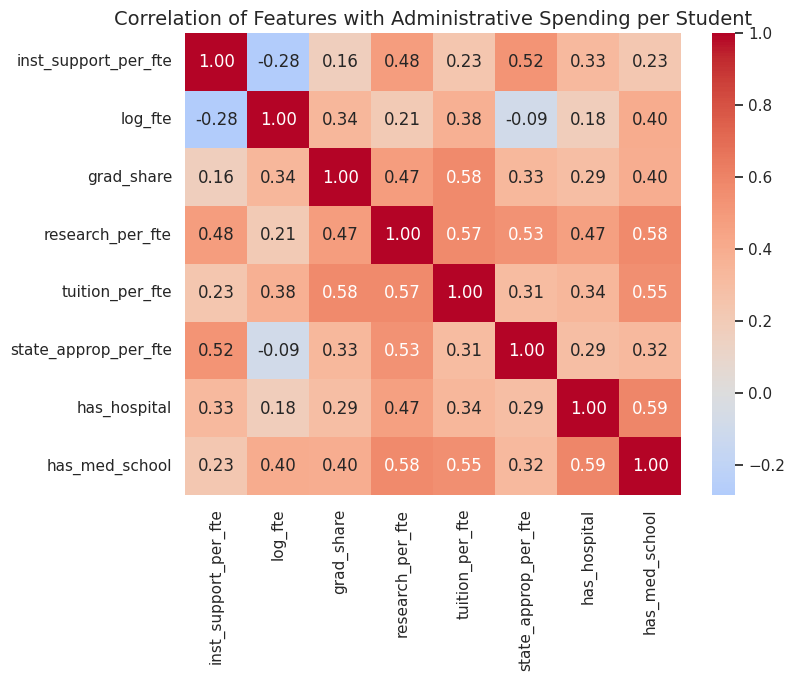

In [128]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_model[[TARGET] + FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of Features with Administrative Spending per Student')
plt.show()

### Step 23: Set the University of Utah aside
To ask "what would the model expect for a school like the U?", the models must never see the U during training. We pull its rows out here and train only on the other schools.

In [129]:
uofu = df_model[df_model['UNITID'] == UOFU_ID].copy()
df_model = df_model[df_model['UNITID'] != UOFU_ID].copy()
print('U of U rows set aside:', len(uofu), '| schools used for modeling:', df_model['UNITID'].nunique())

U of U rows set aside: 3 | schools used for modeling: 786


# 6. Modeling

## Modeling approach
Our target is a number (dollars per student), so this is a **regression** problem. We compare three models from class:

- **Linear Regression:** draws the best straight-line relationship. Easy to explain to leadership, because each feature gets a coefficient. It can miss curved or "it depends" patterns.
- **Decision Tree:** asks a series of yes/no questions (for example, "does the school have a hospital?") to group similar schools. Captures non-linear patterns and interactions, but can overfit if allowed to grow too deep.
- **K-Nearest Neighbors (KNN):** predicts using the most similar schools. Intuitive, but sensitive to the scale of features and slower on large data.

**Metrics:** R-squared (share of the variation explained; higher is better), MAE (typical miss, in dollars per student), and RMSE (like MAE but penalizes big misses more).

**Train/test split:** the data has several years per school, so a plain random split would put the same school in both sets and make scores look better than they are. We split by school (`UNITID`) so each school appears in only one set. We use 80% for training and 20% for testing.

### Step 24: Split into training and test sets

In [130]:
from sklearn.model_selection import GroupShuffleSplit
X, y, groups = df_model[FEATURES], df_model[TARGET], df_model['UNITID']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print('train rows:', len(X_train), '| test rows:', len(X_test))

train rows: 1880 | test rows: 473


### Step 25: Scale the features for Linear Regression and KNN
KNN measures distance, so a feature measured in thousands of dollars would drown out a 0/1 flag. We scale every feature to a similar range, learning the scaling from the training data only. The tree does not need scaling.

In [131]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

### Step 26: A small scoring helper
Every model is scored the same way on the same test data.

In [132]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
results = {}
def score(name, model, X_eval):
    pred = model.predict(X_eval)
    results[name] = {'R2': r2_score(y_test, pred), 'MAE': mean_absolute_error(y_test, pred),
                     'RMSE': mean_squared_error(y_test, pred) ** 0.5}
    return pd.Series(results[name]).round(2)

## Model 1: Linear Regression
### Step 27: Fit and score

In [133]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(X_train_s, y_train)
score('Linear Regression', lin, X_test_s)

,0
R2,0.45
MAE,1755.68
RMSE,3310.47


### Step 28: Which features push spending up or down?
Because the features are scaled, the coefficients are comparable: each one is the change in dollars per student for a one-standard-deviation increase in that feature.

In [134]:
coefs = pd.Series(lin.coef_, index=FEATURES).sort_values()
coefs.round(0)

,0
log_fte,-1857.0
grad_share,-207.0
has_med_school,22.0
tuition_per_fte,522.0
has_hospital,867.0
research_per_fte,1162.0
state_approp_per_fte,1461.0


## Model 2: Decision Tree
### Step 29: Tune and fit
We try several tree depths and minimum leaf sizes, using 5-fold cross-validation grouped by school, and keep the combination with the best R-squared. Shallow trees underfit; very deep trees memorize the training data.

In [135]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
grid = {'max_depth': [3, 5, 8, 12], 'min_samples_leaf': [5, 10, 20]}
search = GridSearchCV(DecisionTreeRegressor(random_state=42), grid, cv=GroupKFold(n_splits=5), scoring='r2')
search.fit(X_train, y_train, groups=g_train)
tree = search.best_estimator_
print('best settings:', search.best_params_)
score('Decision Tree', tree, X_test)

best settings: {'max_depth': 8, 'min_samples_leaf': 10}


,0
R2,0.41
MAE,1734.02
RMSE,3427.26


## Model 3: K-Nearest Neighbors
### Step 30: Tune and fit
We try different numbers of neighbors (k) and whether closer neighbors count more.

In [136]:
from sklearn.neighbors import KNeighborsRegressor
grid = {'n_neighbors': [3, 5, 7, 10, 15, 25], 'weights': ['uniform', 'distance']}
search = GridSearchCV(KNeighborsRegressor(), grid, cv=GroupKFold(n_splits=5), scoring='r2')
search.fit(X_train_s, y_train, groups=g_train)
knn = search.best_estimator_
print('best settings:', search.best_params_)
score('KNN', knn, X_test_s)

best settings: {'n_neighbors': 25, 'weights': 'uniform'}


,0
R2,0.54
MAE,1471.80
RMSE,3019.06


# 7. Evaluation

### Step 31: Compare the three models side by side

In [137]:
comparison = pd.DataFrame(results).T.round(2)
comparison

,R2,MAE,RMSE
Linear Regression,0.45,1755.68,3310.47
Decision Tree,0.41,1734.02,3427.26
KNN,0.54,1471.80,3019.06


In [138]:
best_name = comparison['R2'].idxmax()
print('Best model on the test data (by R2):', best_name)

Best model on the test data (by R2): KNN


### Step 32: What the results mean in business terms
- **Accuracy:** the best model (K-Nearest Neighbors) explains about 54% of the differences in administrative spending per student across public four-year universities. Linear Regression and the Decision Tree each explain about 45%.
- **Typical miss:** the KNN prediction is off by about $1,472 per student on average (MAE). For a school the size of the U (about 33,100 FTE students), that is roughly $49 million a year, so the model is a benchmark, not an exact forecast.
- **Biggest influences:** in the Decision Tree, state appropriations per student (about 48%), tuition per student (about 31%), and school size (about 18%) matter most. In the Linear Regression, larger schools spend less per student (about $1,860 less per standard deviation of size).
- **Why we picked KNN:** it was the most accurate and had the smallest typical miss. Its weakness is that it cannot show which features matter, so we use the Decision Tree and Linear Regression to explain the drivers to leadership.

### Step 33: How does the University of Utah compare?
We ask the best model what a school with the U's profile would be expected to spend per student, then compare it with what the U actually reports. A positive gap means the U spends more on administration than similar schools.

In [139]:
models = {'Linear Regression': (lin, True), 'Decision Tree': (tree, False), 'KNN': (knn, True)}
model, scaled = models[best_name]
X_u = scaler.transform(uofu[FEATURES]) if scaled else uofu[FEATURES]
uofu['expected'] = model.predict(X_u)
uofu['actual'] = df.loc[uofu.index, TARGET]
uofu['gap_pct'] = (uofu['actual'] - uofu['expected']) / uofu['expected'] * 100
uofu[['YEAR', 'actual', 'expected', 'gap_pct']].round(0)

,YEAR,actual,expected,gap_pct
1386,2022,9318.0,4659.0,100.0
3237,2023,11412.0,4461.0,156.0
5086,2024,12006.0,4510.0,166.0


In [140]:
peers24 = df[(df['YEAR'] == 2024) & (df['UNITID'] != UOFU_ID)]
u_row = df[(df['UNITID'] == UOFU_ID) & (df['YEAR'] == 2024)].iloc[0]
similar = peers24[(peers24['has_hospital'] == 1) & (peers24['has_med_school'] == 1)]

print('U of U, 2024: $', round(u_row[TARGET]))
print('All public 4-year peers: median $', round(peers24[TARGET].median()),
      '| U is higher than', round((peers24[TARGET] < u_row[TARGET]).mean() * 100), '% of them')
print('Peers with a hospital and a medical school:', len(similar), 'schools')
print('   median $', round(similar[TARGET].median()), '| 75th percentile $', round(similar[TARGET].quantile(0.75)),
      '| U is higher than', round((similar[TARGET] < u_row[TARGET]).mean() * 100), '% of them')
print('U of U institutional support ($ millions), 2022-2024:',
      (df[df['UNITID'] == UOFU_ID].sort_values('YEAR')['inst_support'] / 1e6).round(0).tolist())

U of U, 2024: $ 12006
All public 4-year peers: median $ 3480 | U is higher than 95 % of them
Peers with a hospital and a medical school: 45 schools
   median $ 6860 | 75th percentile $ 13733 | U is higher than 73 % of them
U of U institutional support ($ millions), 2022-2024: [291.0, 364.0, 398.0]


**Read this carefully:** the U runs a hospital and a medical school, and IPEDS finance data for the U covers the whole system. The U is also much larger than most schools the model learned from, so the model's expected value is a rough guide, not a verdict.

**What the numbers show:** the U's actual spending is well above the model's expectation, and the gap grew from 2022 to 2024. The gap is much larger than the model's typical miss, so it is not just noise. But the next cell shows that, compared only with schools that also have a hospital and a medical school, the U looks much closer to normal. So the U is high against public universities in general, and in the upper-middle range against its most similar peers.

# 8. Final Descriptive Charts
These six charts share one style and are used in the presentation slides.

In [141]:
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize': (8, 5), 'axes.titlesize': 14, 'axes.labelsize': 12})
latest = df_model[df_model['YEAR'] == df_model['YEAR'].max()]

### Chart 1: How much do public universities spend on administration per student?

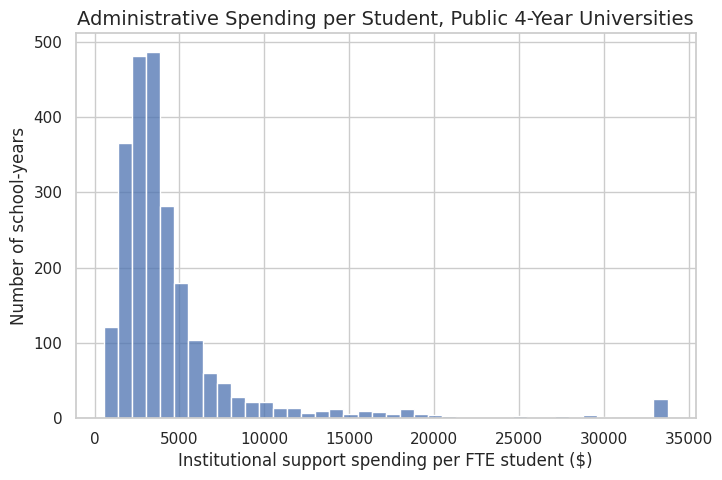

In [142]:
sns.histplot(df_model[TARGET], bins=40)
plt.title('Administrative Spending per Student, Public 4-Year Universities')
plt.xlabel('Institutional support spending per FTE student ($)'); plt.ylabel('Number of school-years')
plt.show()

### Chart 2: Do bigger schools spend less per student?

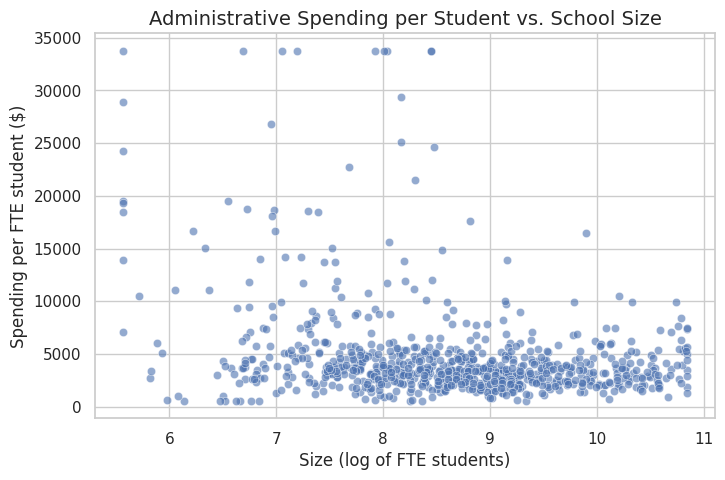

In [143]:
sns.scatterplot(data=latest, x='log_fte', y=TARGET, alpha=0.6)
plt.title('Administrative Spending per Student vs. School Size')
plt.xlabel('Size (log of FTE students)'); plt.ylabel('Spending per FTE student ($)')
plt.show()

### Chart 3: Which model predicts best?

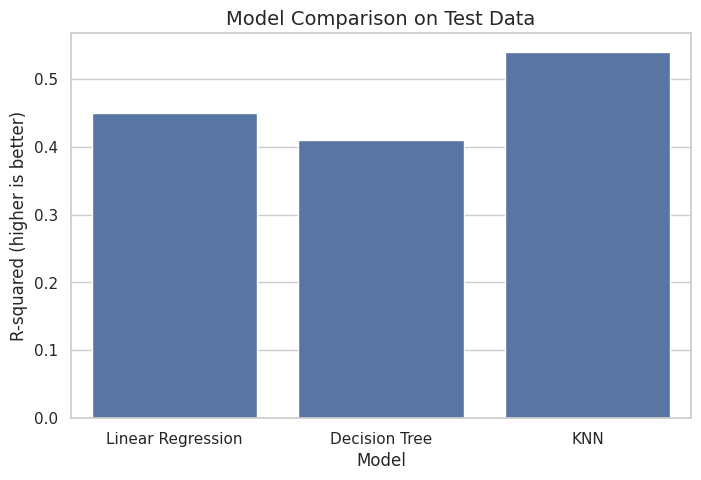

In [144]:
sns.barplot(x=comparison.index, y=comparison['R2'])
plt.title('Model Comparison on Test Data')
plt.xlabel('Model'); plt.ylabel('R-squared (higher is better)')
plt.show()

### Chart 4: What drives administrative spending?

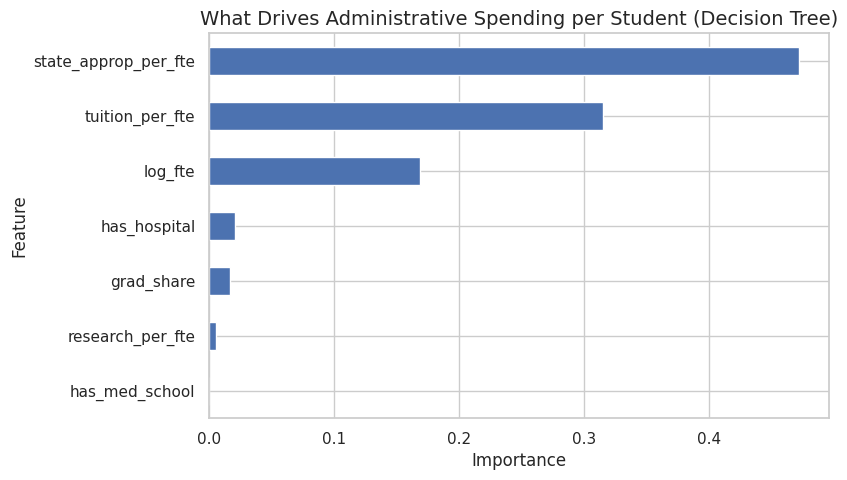

In [145]:
imp = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh()
plt.title('What Drives Administrative Spending per Student (Decision Tree)')
plt.xlabel('Importance'); plt.ylabel('Feature')
plt.show()

### Chart 5: Where does the University of Utah sit among its peers?

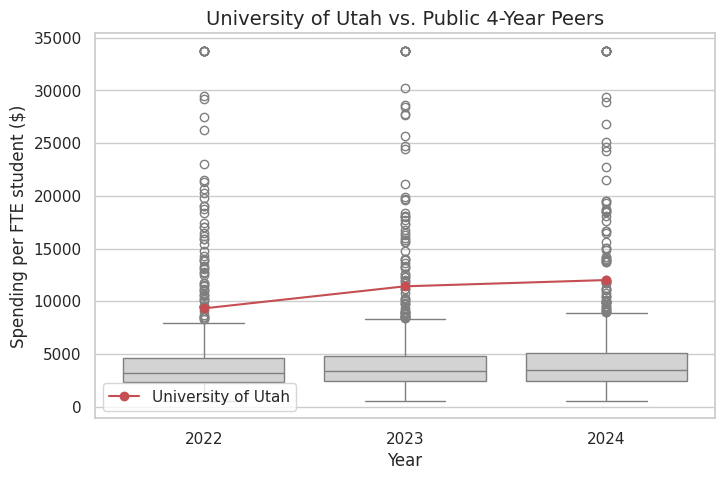

In [146]:
sns.boxplot(data=df_model, x='YEAR', y=TARGET, color='lightgray')
plt.plot(range(len(uofu)), uofu['actual'].values, 'ro-', label='University of Utah')
plt.title('University of Utah vs. Public 4-Year Peers'); plt.legend()
plt.xlabel('Year'); plt.ylabel('Spending per FTE student ($)')
plt.show()

### Chart 6: What the model expects for the University of Utah vs. what it reports

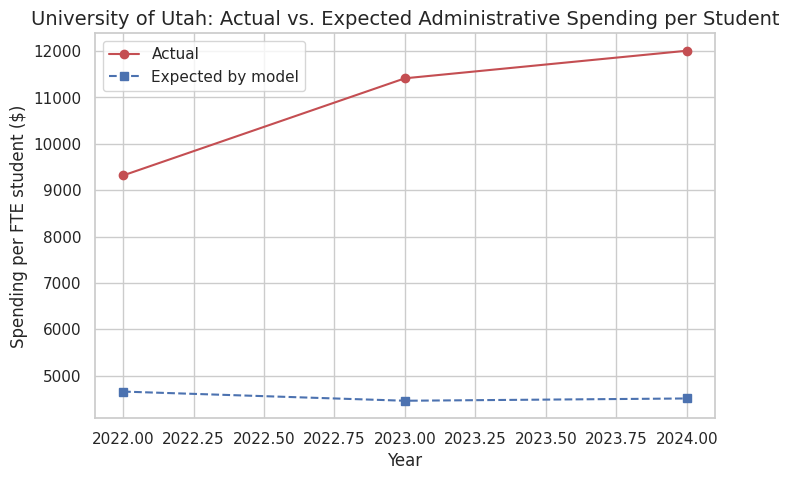

In [147]:
plt.plot(uofu['YEAR'], uofu['actual'], 'ro-', label='Actual')
plt.plot(uofu['YEAR'], uofu['expected'], 'bs--', label='Expected by model')
plt.title('University of Utah: Actual vs. Expected Administrative Spending per Student')
plt.xlabel('Year'); plt.ylabel('Spending per FTE student ($)'); plt.legend()
plt.show()

# 9. Conclusions and Recommendations

**Best model:**
 K-Nearest Neighbors (R-squared 0.54, typical miss about $1,472 per student). It was the most accurate of the three, but it cannot show which features matter, so we used the Decision Tree and Linear Regression to explain the drivers.

**What drives administrative spending:**
state appropriations per student and tuition per student account for most of the Decision Tree's predictive power (about 79% together), followed by school size. Larger schools spend less per student. These are patterns, not proof of cause.

**Where the U stands:**
the U spent $12,006 per FTE student on institutional support in 2024, higher than about 95% of public four-year schools and up from $9,318 in 2022. The model expects about $4,510, but the U is far larger than most schools in the data and its finance data includes a hospital system. Against the 45 schools that also have a hospital and a medical school, the U is at about the 73rd percentile, below their 75th-percentile value of $13,733.

**Recommendations**
1. **Benchmark against matched peers, not all public universities.** Set administrative targets using schools with similar funding, size, hospital, and medical school, instead of a flat percentage cut.
2. **Review the fastest-growing functions first.** Institutional support grew about 37% from 2022 to 2024. Consolidation is most defensible where central services grew faster than enrollment, so look at spending by function before cutting broadly.
3. **Measure what we could not.** Add IPEDS staffing counts, separate the health system from the academic side, and compare spending with outcomes like retention and graduation.

**Limits:**
IPEDS data is self-reported and schools classify spending differently. We measured institutional support spending, a proxy for administrative cost and not staffing itself. The model shows patterns, not cause and effect, and it is not a list of who should lose a job.

**Next steps:**
add private nonprofit schools, try more features such as state or region, and compare staffing counts from the IPEDS Human Resources files with the spending measure.